In [53]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from cmcrameri import cm

In [54]:
def open_kymographs(condition:str, channel:str, ratio_calculation:str = 'RoM', root_path:str = '../LineProfiles/'):
    #Opens the perinuclear(N) and peripheral(P) kymographs generated by the kymo_plotting_notebook jupyter notebook.
    #The root_path is the path to the LineProfiles folder in which each condition has its own folder.
    #Channel can be either red, green, or ratio.
    #Condition can be either TRAK1_kd, TRAK2_kd, MYO19_kd, galactose, galactose_48h, acute_galactose, starvation_control, wt or wt_redraw
    #If you're interested in the ratios you can either choose to look at the ratio of means (RoM) or the mean of ratios (MoR)
    #The output is two dataframes, the first for the perinuclear kymograph and the second for the peripheral kymograph.

    folder = '/kymographs/'
    
    if channel == 'ratio':
        if ratio_calculation == 'MoR':
            filename_N = root_path + condition + folder + 'mean_of_ratios_N.csv'
            filename_P = root_path + condition + folder + 'mean_of_ratios_P.csv'
            filename_N_err = root_path + condition + folder + 'std_of_ratios_N.csv'
            filename_P_err = root_path + condition + folder + 'std_of_ratios_P.csv'
        elif ratio_calculation == 'RoM':
            filename_N = root_path + condition + folder + 'ratio_of_means_N.csv'
            filename_P = root_path + condition + folder + 'ratio_of_means_P.csv'
            filename_N_err = root_path + condition + folder + 'relative_error_ratio_of_means_N.csv'
            filename_P_err = root_path + condition + folder + 'relative_error_ratio_of_means_P.csv'
        elif ratio_calculation == 'median':
            filename_N = root_path + condition + folder + 'median_of_ratios_N.csv'
            filename_P = root_path + condition + folder + 'median_of_ratios_P.csv'
            filename_N_err = root_path + condition + folder + 'std_of_ratios_N.csv'
            filename_P_err = root_path + condition + folder + 'std_of_ratios_P.csv'
        else:
            print('Invalid ratio calculation')
            return
    elif channel == 'red' or channel =='green':
        filename_N = root_path + condition + folder + channel + '_N.csv'
        filename_P = root_path + condition + folder + channel + '_P.csv'
        filename_N_err = root_path + condition + folder + 'std_' + channel + '_N.csv'
        filename_P_err = root_path + condition + folder + 'std_' + channel + '_P.csv'
    else:
        print('Invalid channel')
        return

    df_N = pd.read_csv(filename_N).rename(columns={'Unnamed: 0':'time (min)'})
    df_P = pd.read_csv(filename_P).rename(columns={'Unnamed: 0':'time (min)'})
    df_N_err = pd.read_csv(filename_N_err).rename(columns={'Unnamed: 0':'time (min)'})
    df_P_err = pd.read_csv(filename_P_err).rename(columns={'Unnamed: 0':'time (min)'})
    df_N.set_index('time (min)', inplace=True)
    df_P.set_index('time (min)', inplace=True)
    df_N_err.set_index('time (min)', inplace=True)
    df_P_err.set_index('time (min)', inplace=True)
    
    return df_N, df_P, df_N_err, df_P_err

def plot_green_red(df_green, df_red, cmap_green, cmap_red, tick_locations, tick_replacements):
    fig, ax = plt.subplots(1,2, sharey=True, figsize=(8, 3))
    fig.tight_layout()

    ax[0].imshow(df_green, cmap=cmap_green, vmin=0, vmax=1, aspect='auto', interpolation='none')
    contours = ax[0].contour(df_green, levels=[0.2, 0.4, 0.6, 0.8, 1.0], colors='black', alpha=0.5)
    ax[0].clabel(contours, inline=True, fontsize=10)
    ax[1].imshow(df_red, cmap=cmap_red, vmin=0, vmax=1, aspect='auto', interpolation='none')
    contours = ax[1].contour(df_red, levels=[0.2, 0.4, 0.6, 0.8, 1.0], colors='black', alpha=0.5)
    ax[1].clabel(contours, inline=True, fontsize=10)
    ax[0].set_yticks([0,5,10,15,20,25,30], [0,15,30,45,60,75,90], fontsize=12)
    ax[1].tick_params(left=False)
    ax[0].set_xticks(tick_locations, tick_replacements, fontsize=12)
    ax[1].set_xticks(tick_locations, tick_replacements, fontsize=12)
    ax[0].set_ylabel('Time (min)', fontsize=14)

    return ax


In [55]:
cmap = cm.roma_r
cmap_g = 'Greens'
cmap_r = 'RdPu'

condition = 'wt' # 'TRAK1_kd', 'TRAK1_oe', 'TRAK2_kd', 'TRAK2_oe', 'galactose', 'galactose_48h', 'wt', 'si_control'

In [56]:
df_N_ratio, df_P_ratio, dummy, dummy = open_kymographs(condition, 'ratio', ratio_calculation='median')
df_N_red, df_P_red, dummy, dummy = open_kymographs(condition, 'red', ratio_calculation='MoR')
df_N_green, df_P_green, dummy, dummy = open_kymographs(condition, 'green', ratio_calculation='MoR')

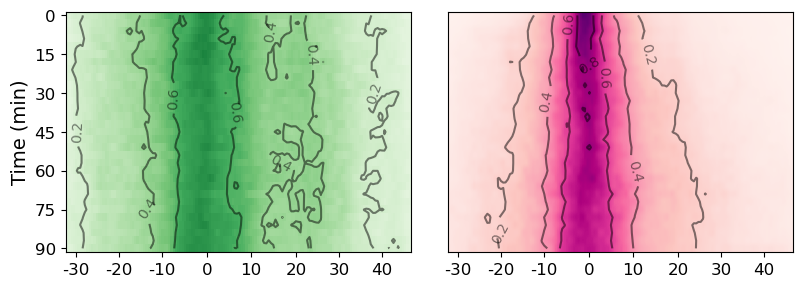

In [57]:
fig, ax = plt.subplots(1,2, sharey=True, figsize=(8, 3))
fig.tight_layout()

ax[0].imshow(df_N_green, cmap=cmap_g, vmin=0, vmax=1, aspect='auto', interpolation='none')
contours = ax[0].contour(df_N_green, levels=[0.2, 0.4, 0.6, 0.8, 1.0], colors='black', alpha=0.5)
ax[0].clabel(contours, inline=True, fontsize=10)
ax[1].imshow(df_N_red, cmap=cmap_r, vmin=0, vmax=1, aspect='auto')
contours = ax[1].contour(df_N_red, levels=[0.2, 0.4, 0.6, 0.8, 1.0], colors='black', alpha=0.5)
ax[1].clabel(contours, inline=True, fontsize=10)
ax[0].set_yticks([0,5,10,15,20,25,30], [0,15,30,45,60,75,90], fontsize=12)
ax[1].tick_params(left=False)
ax[0].set_xticks([4,23,42,62,81,101,120,139], [-30,-20,-10,0,10,20,30,40], fontsize=12)
ax[1].set_xticks([4,23,42,62,81,101,120,139], [-30,-20,-10,0,10,20,30,40], fontsize=12)
ax[0].set_ylabel('Time (min)', fontsize=14)

plt.show()

WT perinuclear

In [58]:
tick_locations = [21,60,99,138]
tick_replacements = [-20,0,20,40]

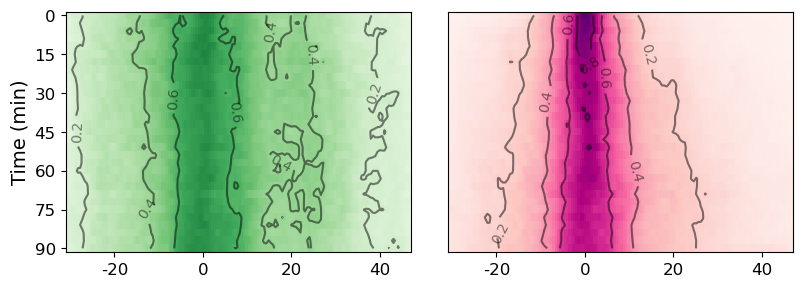

In [61]:
plot_green_red(df_N_green, df_N_red, cmap_g, cmap_r, tick_locations, tick_replacements)
plt.show()
#plt.savefig('_supp_figures/wt_green_red_N.png', dpi=300, bbox_inches='tight')

WT peripheral

In [62]:
tick_locations = [12,51,89,128]
tick_replacements = [0,20,40,60]

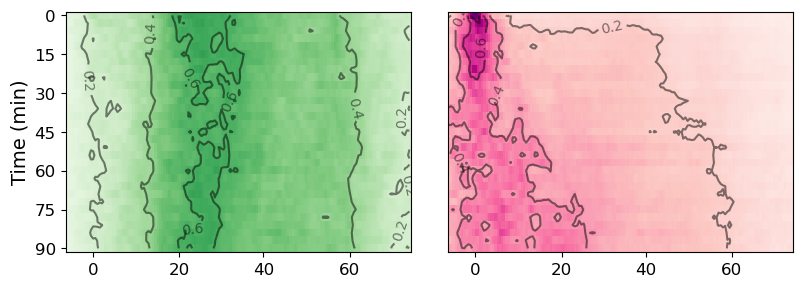

In [65]:
plot_green_red(df_P_green, df_P_red, cmap_g, cmap_r, tick_locations, tick_replacements)
plt.show()
#plt.savefig('_supp_figures/wt_green_red_P.png', dpi=300, bbox_inches='tight')

In [69]:
condition = 'TRAK1_kd'

df_N_ratio, df_P_ratio, dummy, dummy = open_kymographs(condition, 'ratio', ratio_calculation='median')
df_N_red, df_P_red, dummy, dummy = open_kymographs(condition, 'red', ratio_calculation='MoR')
df_N_green, df_P_green, dummy, dummy = open_kymographs(condition, 'green', ratio_calculation='MoR')

TRAK1 kd perinuclear

In [70]:
tick_locations = [21,60,99,138]
tick_replacements = [-20,0,20,40]

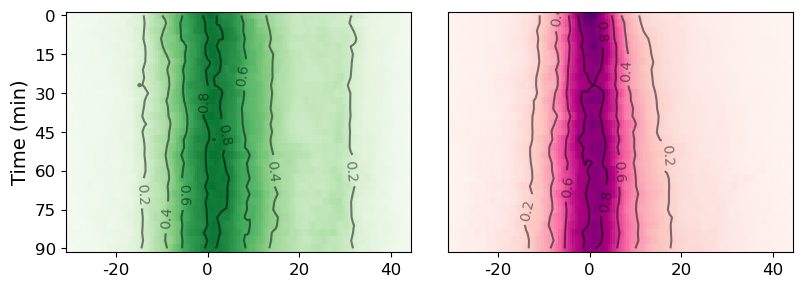

In [73]:
plot_green_red(df_N_green, df_N_red, cmap_g, cmap_r, tick_locations, tick_replacements)
plt.show()
#plt.savefig('_supp_figures/trak1_kd_green_red_N.png', dpi=300, bbox_inches='tight')

TRAK1 kd peripheral

In [76]:
tick_locations = [5,44,83,122]
tick_replacements = [0,20,40,60]

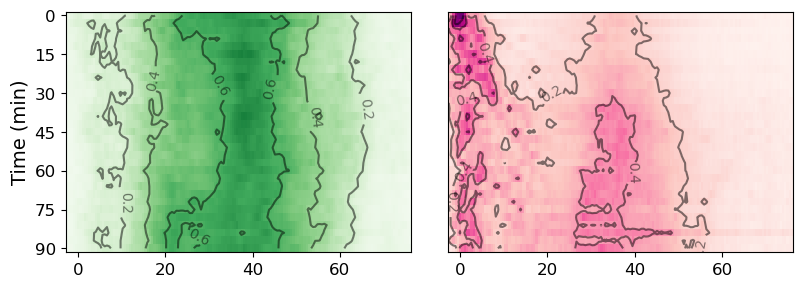

In [77]:
plot_green_red(df_P_green, df_P_red, cmap_g, cmap_r, tick_locations, tick_replacements)
plt.show()
#plt.savefig('_supp_figures/trak1_kd_green_red_P.png', dpi=300, bbox_inches='tight')

ratio

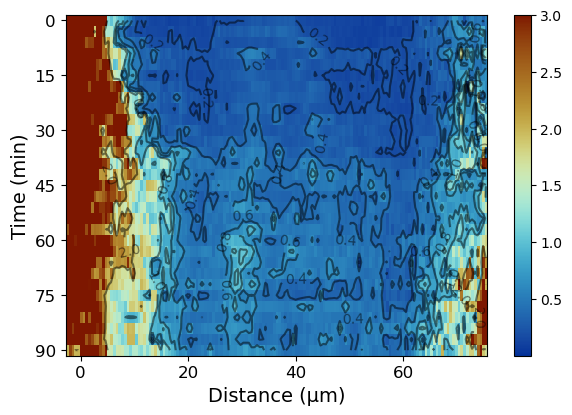

In [78]:
fig, ax = plt.subplots(figsize=(6, 4))
fig.tight_layout()

plt.imshow(df_P_ratio, cmap=cmap, vmin=0, vmax=3.0, aspect='auto', interpolation='none')
plt.colorbar(ticks=[0.5,1.0,1.5,2.0,2.5,3.0])
contours = plt.contour(df_P_ratio, levels=[0.2, 0.4, 0.6, 0.8, 1.0, 2.0], colors='black', alpha=0.5)
plt.clabel(contours, inline=True, fontsize=10)
#Axes tick labelling
plt.ylabel('Time (min)', fontsize=14)
plt.yticks([0,5,10,15,20,25,30], [0,15,30,45,60,75,90], rotation=0, fontsize=12)
plt.xlabel('Distance (µm)', fontsize=14)
plt.xticks(tick_locations, tick_replacements, rotation=0, fontsize=12)

plt.show()
#plt.savefig('_supp_figures/trak1_kd_ratio_P.png', dpi=300, bbox_inches='tight')

In [79]:
condition = 'TRAK2_kd'

df_N_ratio, df_P_ratio, dummy, dummy = open_kymographs(condition, 'ratio', ratio_calculation='median')
df_N_red, df_P_red, dummy, dummy = open_kymographs(condition, 'red', ratio_calculation='MoR')
df_N_green, df_P_green, dummy, dummy = open_kymographs(condition, 'green', ratio_calculation='MoR')

TRAK2 kd perinuclear

In [80]:
tick_locations = [24,63,102,141]
tick_replacements = [-20,0,20,40]

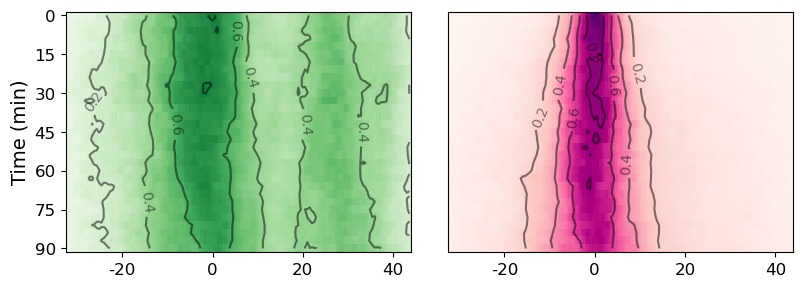

In [82]:
plot_green_red(df_N_green, df_N_red, cmap_g, cmap_r, tick_locations, tick_replacements)
plt.show()
#plt.savefig('_supp_figures/trak2_kd_green_red_N.png', dpi=300, bbox_inches='tight')

TRAK2 kd peripheral

In [83]:
tick_locations = [6,45,84,124]
tick_replacements = [0,20,40,60]

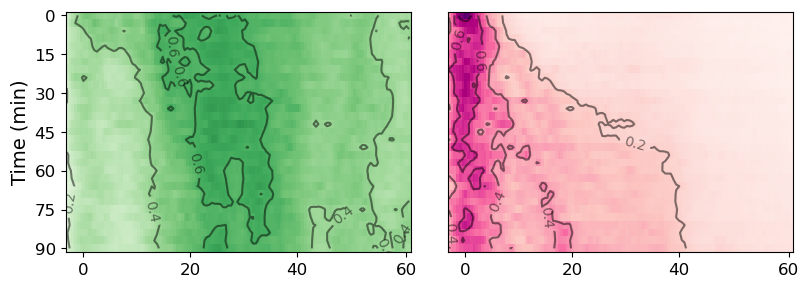

In [86]:
plot_green_red(df_P_green, df_P_red, cmap_g, cmap_r, tick_locations, tick_replacements)
plt.show()
#plt.savefig('_supp_figures/trak2_kd_green_red_P.png', dpi=300, bbox_inches='tight')

ratio

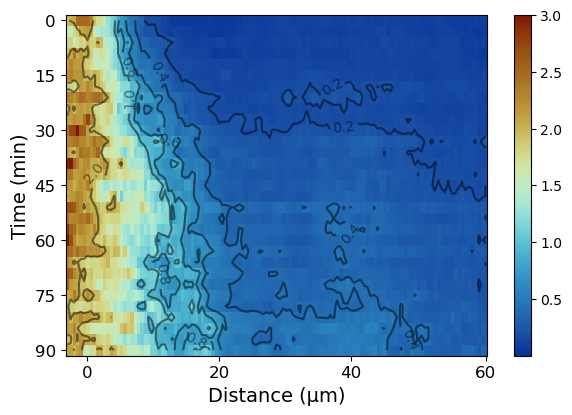

In [89]:
fig, ax = plt.subplots(figsize=(6, 4))
fig.tight_layout()

plt.imshow(df_P_ratio, cmap=cmap, vmin=0, vmax=3.0, aspect='auto', interpolation='none')
plt.colorbar(ticks=[0.5,1.0,1.5,2.0,2.5,3.0])
contours = plt.contour(df_P_ratio, levels=[0.2, 0.4, 0.6, 0.8, 1.0, 2.0], colors='black', alpha=0.5)
plt.clabel(contours, inline=True, fontsize=10)
#Axes tick labelling
plt.ylabel('Time (min)', fontsize=14)
plt.yticks([0,5,10,15,20,25,30], [0,15,30,45,60,75,90], rotation=0, fontsize=12)
plt.xlabel('Distance (µm)', fontsize=14)
plt.xticks(tick_locations, tick_replacements, rotation=0, fontsize=12)

plt.show()
#plt.savefig('_supp_figures/trak2_kd_ratio_P.png', dpi=300, bbox_inches='tight')

In [90]:
condition = 'TRAK1_oe'

df_N_ratio, df_P_ratio, dummy, dummy = open_kymographs(condition, 'ratio', ratio_calculation='median')
df_N_red, df_P_red, dummy, dummy = open_kymographs(condition, 'red', ratio_calculation='MoR')
df_N_green, df_P_green, dummy, dummy = open_kymographs(condition, 'green', ratio_calculation='MoR')

TRAK1 oe perinuclear

In [91]:
tick_locations = [18,57,96,135]
tick_replacements = [-20,0,20,40]

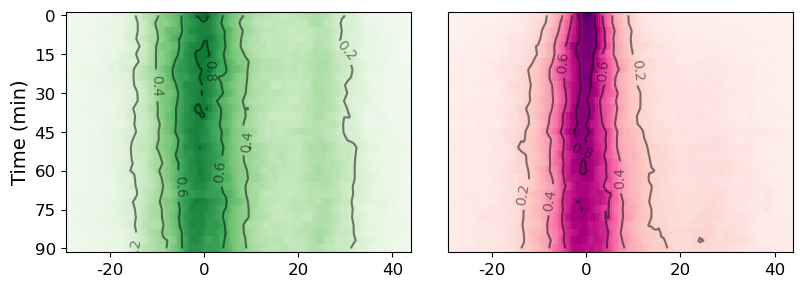

In [94]:
plot_green_red(df_N_green, df_N_red, cmap_g, cmap_r, tick_locations, tick_replacements)
plt.show()
#plt.savefig('_supp_figures/trak1_oe_green_red_N.png', dpi=300, bbox_inches='tight')

In [95]:
condition = 'TRAK2_oe'

df_N_ratio, df_P_ratio, dummy, dummy = open_kymographs(condition, 'ratio', ratio_calculation='median')
df_N_red, df_P_red, dummy, dummy = open_kymographs(condition, 'red', ratio_calculation='MoR')
df_N_green, df_P_green, dummy, dummy = open_kymographs(condition, 'green', ratio_calculation='MoR')

TRAK2 oe perinuclear

In [98]:
tick_locations = [19,58,97,136]
tick_replacements = [-20,0,20,40]

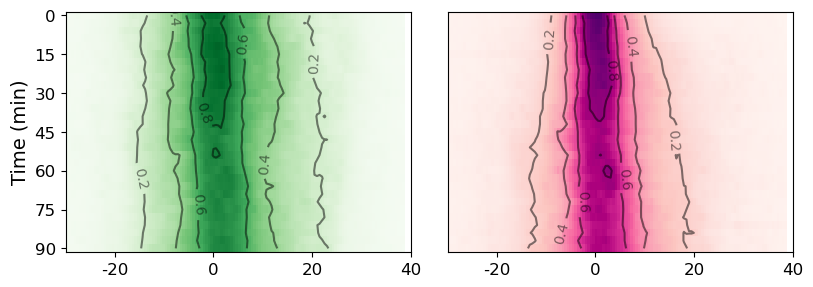

In [101]:
plot_green_red(df_N_green, df_N_red, cmap_g, cmap_r, tick_locations, tick_replacements)
plt.show()
#plt.savefig('_supp_figures/trak2_oe_green_red_N.png', dpi=300, bbox_inches='tight')

In [102]:
condition = 'galactose'

df_N_ratio, df_P_ratio, dummy, dummy = open_kymographs(condition, 'ratio', ratio_calculation='median')
df_N_red, df_P_red, dummy, dummy = open_kymographs(condition, 'red', ratio_calculation='MoR')
df_N_green, df_P_green, dummy, dummy = open_kymographs(condition, 'green', ratio_calculation='MoR')

galactose O/N perinuclear

In [103]:
tick_locations = [22,61,100,138]
tick_replacements = [-20,0,20,40]

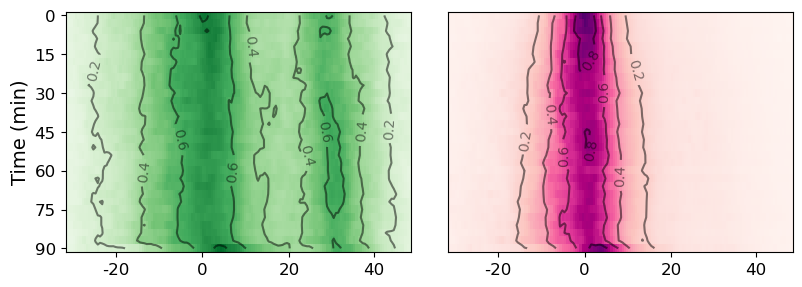

In [106]:
plot_green_red(df_N_green, df_N_red, cmap_g, cmap_r, tick_locations, tick_replacements)
plt.show()
#plt.savefig('_supp_figures/gal_on_green_red_N.png', dpi=300, bbox_inches='tight')

galactose O/N peripheral

In [107]:
tick_locations = [10,49,88,127]
tick_replacements = [0,20,40,60]

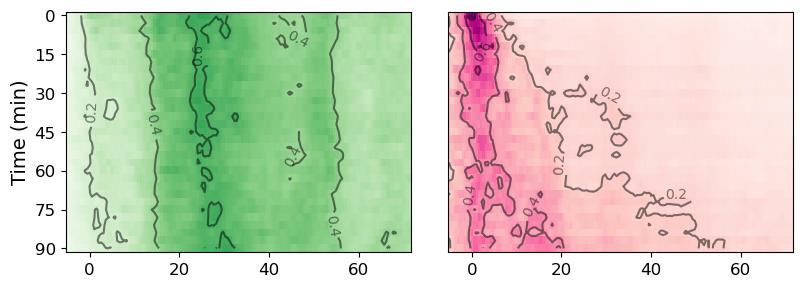

In [110]:
plot_green_red(df_P_green, df_P_red, cmap_g, cmap_r, tick_locations, tick_replacements)
plt.show()
#plt.savefig('_supp_figures/gal_on_green_red_P.png', dpi=300, bbox_inches='tight')

ratio

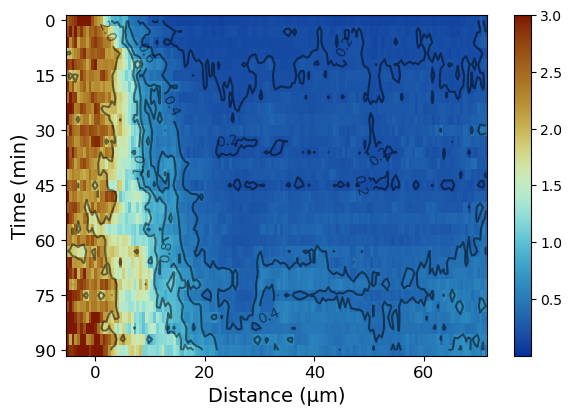

In [113]:
fig, ax = plt.subplots(figsize=(6, 4))
fig.tight_layout()

plt.imshow(df_P_ratio, cmap=cmap, vmin=0, vmax=3.0, aspect='auto', interpolation='none')
plt.colorbar(ticks=[0.5,1.0,1.5,2.0,2.5,3.0])
contours = plt.contour(df_P_ratio, levels=[0.2, 0.4, 0.6, 0.8, 1.0, 2.0], colors='black', alpha=0.5)
plt.clabel(contours, inline=True, fontsize=10)
#Axes tick labelling
plt.ylabel('Time (min)', fontsize=14)
plt.yticks([0,5,10,15,20,25,30], [0,15,30,45,60,75,90], rotation=0, fontsize=12)
plt.xlabel('Distance (µm)', fontsize=14)
plt.xticks(tick_locations, tick_replacements, rotation=0, fontsize=12)

plt.show()
#plt.savefig('_supp_figures/gal_on_ratio_P.png', dpi=300, bbox_inches='tight')

In [114]:
condition = 'galactose_48h'

df_N_ratio, df_P_ratio, dummy, dummy = open_kymographs(condition, 'ratio', ratio_calculation='median')
df_N_red, df_P_red, dummy, dummy = open_kymographs(condition, 'red', ratio_calculation='MoR')
df_N_green, df_P_green, dummy, dummy = open_kymographs(condition, 'green', ratio_calculation='MoR')

galactose 48h perinuclear

In [115]:
tick_locations = [20,59,98,136]
tick_replacements = [-20,0,20,40]

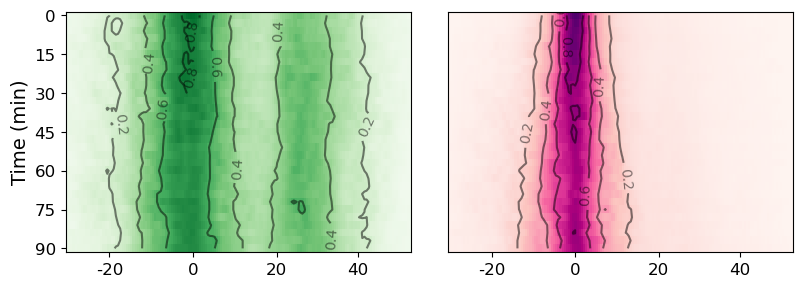

In [118]:
plot_green_red(df_N_green, df_N_red, cmap_g, cmap_r, tick_locations, tick_replacements)
plt.show()
#plt.savefig('_supp_figures/gal_48_green_red_N.png', dpi=300, bbox_inches='tight')

galactose 48h peripheral

In [119]:
tick_locations = [8,47,86,125]
tick_replacements = [0,20,40,60]

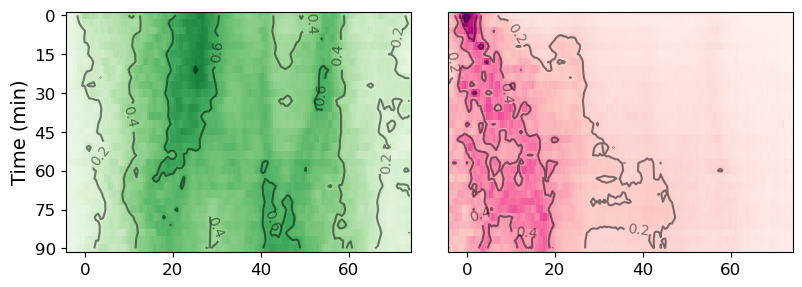

In [122]:
plot_green_red(df_P_green, df_P_red, cmap_g, cmap_r, tick_locations, tick_replacements)
plt.show()
#plt.savefig('_supp_figures/gal_48_green_red_P.png', dpi=300, bbox_inches='tight')

ratio

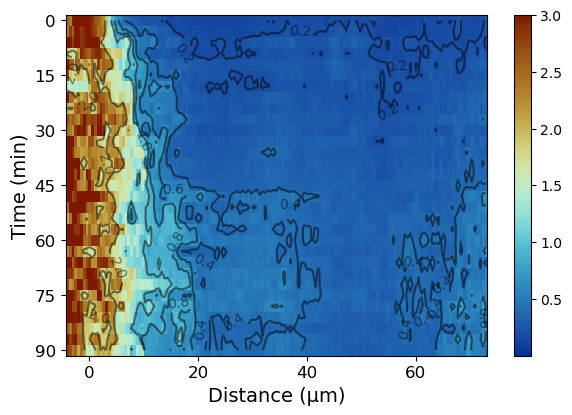

In [125]:
fig, ax = plt.subplots(figsize=(6, 4))
fig.tight_layout()

plt.imshow(df_P_ratio, cmap=cmap, vmin=0, vmax=3.0, aspect='auto', interpolation='none')
plt.colorbar(ticks=[0.5,1.0,1.5,2.0,2.5,3.0])
contours = plt.contour(df_P_ratio, levels=[0.2, 0.4, 0.6, 0.8, 1.0, 2.0], colors='black', alpha=0.5)
plt.clabel(contours, inline=True, fontsize=10)
#Axes tick labelling
plt.ylabel('Time (min)', fontsize=14)
plt.yticks([0,5,10,15,20,25,30], [0,15,30,45,60,75,90], rotation=0, fontsize=12)
plt.xlabel('Distance (µm)', fontsize=14)
plt.xticks(tick_locations, tick_replacements, rotation=0, fontsize=12)

plt.show()
#plt.savefig('_supp_figures/gal_48_ratio_P.png', dpi=300, bbox_inches='tight')

In [126]:
condition = 'si_control'

df_N_ratio, df_P_ratio, dummy, dummy = open_kymographs(condition, 'ratio', ratio_calculation='median')
df_N_red, df_P_red, dummy, dummy = open_kymographs(condition, 'red', ratio_calculation='MoR')
df_N_green, df_P_green, dummy, dummy = open_kymographs(condition, 'green', ratio_calculation='MoR')

si control perinuclear

In [127]:
tick_locations = [26,65,104,143]
tick_replacements = [-20,0,20,40]

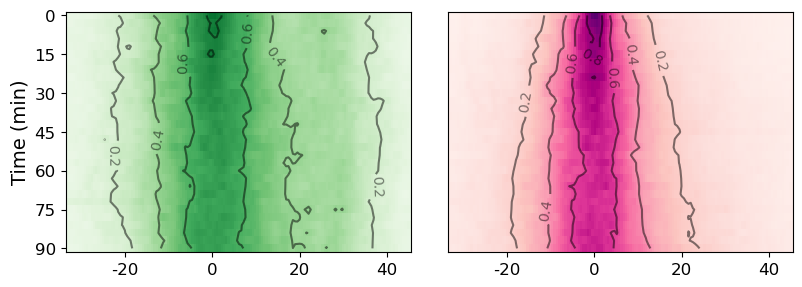

In [130]:
plot_green_red(df_N_green, df_N_red, cmap_g, cmap_r, tick_locations, tick_replacements)
plt.show()
#plt.savefig('_supp_figures/si_ctrl_green_red_N.png', dpi=300, bbox_inches='tight')

ratio

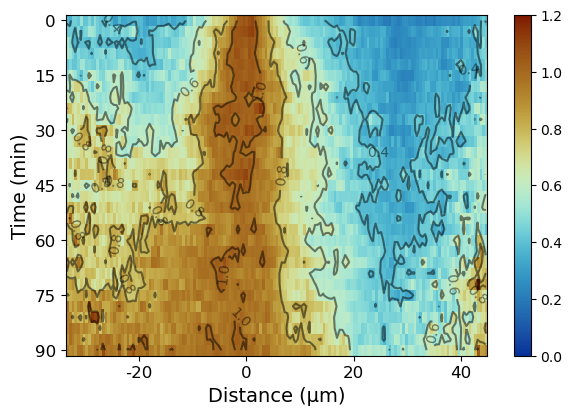

In [133]:
fig, ax = plt.subplots(figsize=(6, 4))
fig.tight_layout()

plt.imshow(df_N_ratio, cmap=cmap, vmin=0, vmax=1.2, aspect='auto', interpolation='none')
plt.colorbar(ticks=[0,0.2,0.4,0.6,0.8,1.0,1.2])
contours = plt.contour(df_N_ratio, levels=[0.4, 0.6, 0.8, 1.0], colors='black', alpha=0.5)
plt.clabel(contours, inline=True, fontsize=10)
#Axes tick labelling
plt.ylabel('Time (min)', fontsize=14)
plt.yticks([0,5,10,15,20,25,30], [0,15,30,45,60,75,90], rotation=0, fontsize=12)
plt.xlabel('Distance (µm)', fontsize=14)
plt.xticks(tick_locations, tick_replacements, rotation=0, fontsize=12)

plt.show()
#plt.savefig('_supp_figures/si_ctrl_ratio_N.png', dpi=300, bbox_inches='tight')

si control peripheral

In [134]:
tick_locations = [7,46,85]
tick_replacements = [0,20,40]

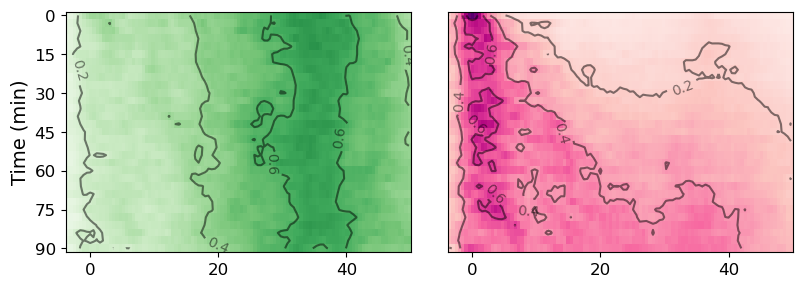

In [137]:
plot_green_red(df_P_green, df_P_red, cmap_g, cmap_r, tick_locations, tick_replacements)
plt.show()
#plt.savefig('_supp_figures/si_ctrl_green_red_P.png', dpi=300, bbox_inches='tight')

ratio

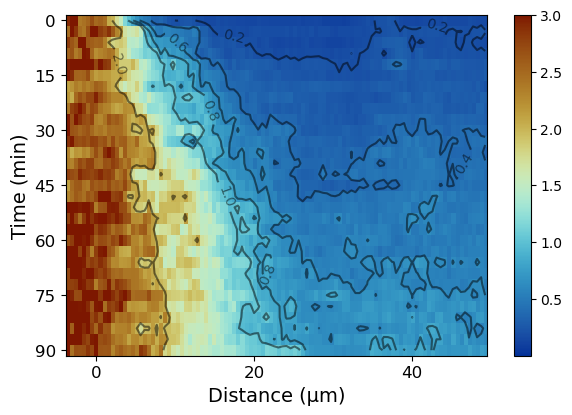

In [140]:
fig, ax = plt.subplots(figsize=(6, 4))
fig.tight_layout()

plt.imshow(df_P_ratio, cmap=cmap, vmin=0, vmax=3.0, aspect='auto', interpolation='none')
plt.colorbar(ticks=[0.5,1.0,1.5,2.0,2.5,3.0])
contours = plt.contour(df_P_ratio, levels=[0.2, 0.4, 0.6, 0.8, 1.0, 2.0], colors='black', alpha=0.5)
plt.clabel(contours, inline=True, fontsize=10)
#Axes tick labelling
plt.ylabel('Time (min)', fontsize=14)
plt.yticks([0,5,10,15,20,25,30], [0,15,30,45,60,75,90], rotation=0, fontsize=12)
plt.xlabel('Distance (µm)', fontsize=14)
plt.xticks(tick_locations, tick_replacements, rotation=0, fontsize=12)

plt.show()
#plt.savefig('_supp_figures/si_ctrl_ratio_P.png', dpi=300, bbox_inches='tight')

In [179]:
df_P_green.columns.values

array(['-3.605', '-3.09', '-2.575', '-2.06', '-1.545', '-1.03', '-0.515',
       '0.0', '0.515', '1.03', '1.545', '2.06', '2.575', '3.09', '3.605',
       '4.12', '4.635', '5.15', '5.665', '6.18', '6.695', '7.21', '7.725',
       '8.24', '8.755', '9.27', '9.785', '10.3', '10.815', '11.33',
       '11.845', '12.36', '12.875', '13.39', '13.905', '14.42', '14.935',
       '15.45', '15.965', '16.48', '16.995', '17.51', '18.025', '18.54',
       '19.055', '19.57', '20.085', '20.6', '21.115', '21.63', '22.145',
       '22.66', '23.175', '23.69', '24.205', '24.72', '25.235', '25.75',
       '26.265', '26.78', '27.295', '27.81', '28.325', '28.84', '29.355',
       '29.87', '30.385', '30.9', '31.415', '31.93', '32.445', '32.96',
       '33.475', '33.99', '34.505', '35.02', '35.535', '36.05', '36.565',
       '37.08', '37.595', '38.11', '38.625', '39.14', '39.655', '40.17',
       '40.685', '41.2', '41.715', '42.23', '42.745', '43.26', '43.775',
       '44.29', '44.805', '45.32', '45.835', '46.3

In [171]:
np.where(df_P_green.columns.values == '0.0')

(array([7], dtype=int64),)